nov 23th

In [ ]:
# import xarray as xr
# from scipy.interpolate import NearestNDInterpolator
from scipy.interpolate import griddata
from scipy.interpolate import PchipInterpolator, pchip_interpolate

import pandas as pd
import numpy as np
# from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

from pyproj import Transformer

### bringing in sed (TOS)

this will be the alpha dataset

In [23]:
dtos = pd.read_csv('..\\data\\mcs02A\\TOS.csv', sep='\\s+', skiprows=1,
                 names=['x', 'y', 'z_sed'])

In [24]:
t = Transformer.from_crs('EPSG:32610', 'EPSG:4326', always_xy=True)
dtos['long'], dtos['lat'] = t.transform(dtos['x'].values, dtos['y'].values)

dtos = dtos[['x', 'y', 'lat', 'long', 'z_sed']]

print(dtos)

           x        y        lat        long  z_sed
0     257059  5255391  47.406716 -126.220174  3.123
1     257053  5255393  47.406732 -126.220255  3.124
2     257047  5255395  47.406748 -126.220335  3.124
3     257041  5255397  47.406763 -126.220416  3.125
4     257035  5255399  47.406779 -126.220496  3.125
...      ...      ...        ...         ...    ...
7213  214715  5270861  47.528489 -126.790262  3.275
7214  214709  5270863  47.528504 -126.790343  3.275
7215  214703  5270865  47.528519 -126.790424  3.275
7216  214697  5270867  47.528535 -126.790505  3.274
7217  214692  5270870  47.528560 -126.790573  3.274

[7218 rows x 5 columns]


### bringing in crust (TOC)

this will be the omega dataset

In [25]:
dtoc = pd.read_csv('..\\data\\mcs02A\\TOC.csv', sep='\\s+', skiprows=1, 
                 names=['x', 'y', 'z_crust'])

In [26]:
t = Transformer.from_crs('EPSG:32610', 'EPSG:4326', always_xy=True)
dtoc['long'], dtoc['lat'] = t.transform(dtoc['x'].values, dtoc['y'].values)

dtoc = dtoc[['x', 'y', 'lat', 'long', 'z_crust']]

print(dtoc)

           x        y        lat        long  z_crust
0     257059  5255391  47.406716 -126.220174    5.273
1     257053  5255393  47.406732 -126.220255    5.276
2     257047  5255395  47.406748 -126.220335    5.280
3     257041  5255397  47.406763 -126.220416    5.281
4     257035  5255399  47.406779 -126.220496    5.289
...      ...      ...        ...         ...      ...
7151  214715  5270861  47.528489 -126.790262    4.893
7152  214709  5270863  47.528504 -126.790343    4.892
7153  214703  5270865  47.528519 -126.790424    4.891
7154  214697  5270867  47.528535 -126.790505    4.890
7155  214692  5270870  47.528560 -126.790573    4.890

[7156 rows x 5 columns]


c=x, s=z

In [27]:
# converting directions to numpy array (replacement to .values)

c_xy = dtoc[['x','y']].to_numpy()
s_xy = dtos[['x','y']].to_numpy()

In [28]:
print(f'c_xy:\n{c_xy[0:5]}')
print(f's_xy:\n{s_xy[0:5]}')

c_xy:
[[ 257059 5255391]
 [ 257053 5255393]
 [ 257047 5255395]
 [ 257041 5255397]
 [ 257035 5255399]]
s_xy:
[[ 257059 5255391]
 [ 257053 5255393]
 [ 257047 5255395]
 [ 257041 5255397]
 [ 257035 5255399]]


In [29]:
# normalizes a 2D vector into unit vectors with a length of 1
origin=c_xy[0]
d_c = c_xy[-1] - c_xy[0]
d_c = d_c / np.hypot(*d_c)

# distance along the line for both datasets

c_dis = (c_xy - c_xy[0]) @ d_c

In [31]:
d_s = s_xy[-1] - s_xy[0]
d_s = d_s / np.hypot(*d_s)

s_dis = (s_xy - s_xy[0]) @ d_s

In [33]:
# now converting crust depths to numpy array
c_z = dtoc['z_crust'].to_numpy()

In [34]:
order = np.argsort(c_dis)  # indices that sorts c from smallest to largest
c_dis, c_z = c_dis[order], c_z[order]

ensures original values are increasing and duplicates are removed (required for interp)

In [35]:
c_dis, idx = np.unique(c_dis, return_index=True)
c_z = c_z[idx]

In [36]:
print(f'min: {c_z.min()}, max: {c_z.max()}')

min: 4.848, max: 5.346


now we build the interpolator and evaluate at every sediment position

[pchipinterp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html#scipy.interpolate.PchipInterpolator)

from claude: "we fit one continuous curve through all the crust points, then reads that curve at each sediment distance (s_dis is a list of distances where you want a crust depth)"

In [37]:
interp_crust = pchip_interpolate(c_dis, c_z, s_dis)

making any values outside the range as NaNs

In [38]:
P = PchipInterpolator(c_dis, c_z, extrapolate=False)
interp_crust = P(s_dis)

In [39]:
dtos['z_crust'] = interp_crust

In [42]:
print(dtos)

           x        y        lat        long  z_sed  z_crust
0     257059  5255391  47.406716 -126.220174  3.123    5.273
1     257053  5255393  47.406732 -126.220255  3.124    5.276
2     257047  5255395  47.406748 -126.220335  3.124    5.280
3     257041  5255397  47.406763 -126.220416  3.125    5.281
4     257035  5255399  47.406779 -126.220496  3.125    5.289
...      ...      ...        ...         ...    ...      ...
7213  214715  5270861  47.528489 -126.790262  3.275    4.893
7214  214709  5270863  47.528504 -126.790343  3.275    4.892
7215  214703  5270865  47.528519 -126.790424  3.275    4.891
7216  214697  5270867  47.528535 -126.790505  3.274    4.890
7217  214692  5270870  47.528560 -126.790573  3.274    4.890

[7218 rows x 6 columns]


ensure it all lines up

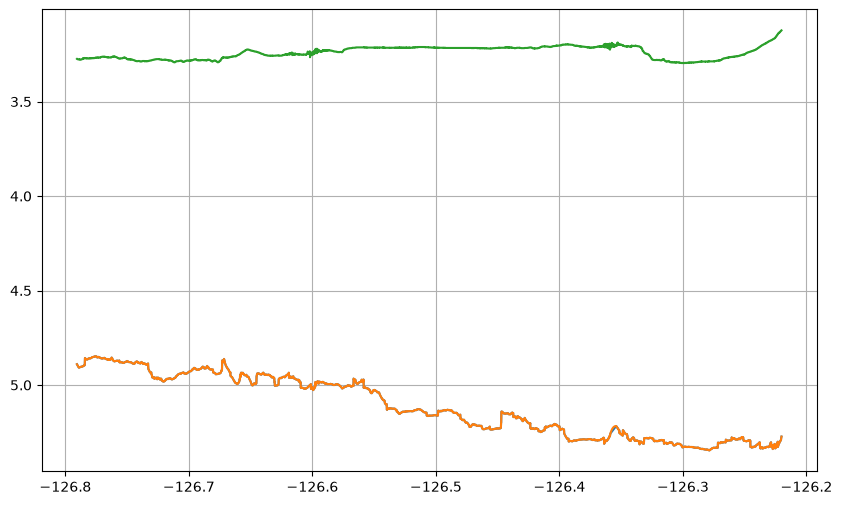

In [69]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(dtoc['long'], dtoc['z_crust'])
ax.plot(dtos['long'], dtos['z_crust'])
ax.plot(dtos['long'], dtos['z_sed'])
ax.invert_yaxis()

plt.grid()
plt.show()

In [44]:
# building a new dataframe

df = pd.DataFrame({
    'x': dtos['x'],
    'y': dtos['y'],
    'long': dtos['long'],
    'lat': dtos['lat'],
    'z_sed': dtos['z_sed'],
    'z_crust': dtos['z_crust']})

In [45]:
mask = (s_dis >= c_dis.min()) & (s_dis <= c_dis.max())

df['x'] = df['x'][mask]
df['y'] = df['y'][mask]
df['long'] = df['long'][mask]
df['lat'] = df['lat'][mask]
df['z_sed'] = df['z_sed'][mask]

df = df.dropna(how='all').reset_index(drop=True)

In [46]:
print(df.head())

        x        y        long        lat  z_sed  z_crust
0  257059  5255391 -126.220174  47.406716  3.123    5.273
1  257053  5255393 -126.220255  47.406732  3.124    5.276
2  257047  5255395 -126.220335  47.406748  3.124    5.280
3  257041  5255397 -126.220416  47.406763  3.125    5.281
4  257035  5255399 -126.220496  47.406779  3.125    5.289


In [47]:
v_crust = 5910 # m/s
v_sed = 2000 # m/s
v_wat = 1500 # m/s

df['depth_m'] = (v_wat * (df['z_sed'] / 2) + (v_sed * (df['z_crust'] - df['z_sed']) / 2)).to_numpy()
df['depth_km'] = df['depth_m'] / 1000

In [48]:
print(df.head())

        x        y        long        lat  z_sed  z_crust  depth_m  depth_km
0  257059  5255391 -126.220174  47.406716  3.123    5.273  4492.25   4.49225
1  257053  5255393 -126.220255  47.406732  3.124    5.276  4495.00   4.49500
2  257047  5255395 -126.220335  47.406748  3.124    5.280  4499.00   4.49900
3  257041  5255397 -126.220416  47.406763  3.125    5.281  4499.75   4.49975
4  257035  5255399 -126.220496  47.406779  3.125    5.289  4507.75   4.50775


### downloading no grav...

In [ ]:
# df.to_csv('..\\created_data\\mcs\\nov23_toc_tos_interp.csv', index=False)

## old stuff

In [49]:
dg = pd.read_csv("..\\created_data\\FA.csv", header=None, skiprows=1, names=['long', 'lat', 'FA'])
print(dg)

             long        lat          FA
0     -133.000003  37.983334  -20.522749
1     -133.000003  38.100001  -24.824638
2     -133.000003  38.216667  -31.192137
3     -133.000003  38.333334  -38.186611
4     -133.000003  38.450001  -32.169643
...           ...        ...         ...
16693 -119.000003  53.500001  111.308601
16694 -119.000003  53.616668   50.057011
16695 -119.000003  53.733334   37.020630
16696 -119.000003  53.850001    4.265869
16697 -119.000003  53.966668  -10.105060

[16698 rows x 3 columns]


"This code takes free-air gravity (FA) measured at one set of locations (dg) and estimates what it would be at a different set of locations (df, your profile points)"

In [50]:
df['FA'] = griddata((dg[['long','lat']].values), dg['FA'].values, df[['long','lat']].values, method='linear')

In [51]:
print(df)

           x        y        long        lat  z_sed  z_crust  depth_m  \
0     257059  5255391 -126.220174  47.406716  3.123    5.273  4492.25   
1     257053  5255393 -126.220255  47.406732  3.124    5.276  4495.00   
2     257047  5255395 -126.220335  47.406748  3.124    5.280  4499.00   
3     257041  5255397 -126.220416  47.406763  3.125    5.281  4499.75   
4     257035  5255399 -126.220496  47.406779  3.125    5.289  4507.75   
...      ...      ...         ...        ...    ...      ...      ...   
7213  214715  5270861 -126.790262  47.528489  3.275    4.893  4074.25   
7214  214709  5270863 -126.790343  47.528504  3.275    4.892  4073.25   
7215  214703  5270865 -126.790424  47.528519  3.275    4.891  4072.25   
7216  214697  5270867 -126.790505  47.528535  3.274    4.890  4071.50   
7217  214692  5270870 -126.790573  47.528560  3.274    4.890  4071.50   

      depth_km         FA  
0      4.49225 -23.555516  
1      4.49500 -23.567787  
2      4.49900 -23.580057  
3      4.49

### downloading w grav...

In [52]:
df.to_csv('..\\created_data\\mcs\\02A_nov23_FA_toc_tos_interp.csv', index=False)